This notebook is designed to analyze and compare the performance for V2 screens datasets processed using ScreenPro2 to improve DevOps objectives. The primary focus is on evaluating the discrepancies between the ScreenProcessing guide level scores and the ScreenPro2 scores. This analysis will help in identifying areas for improvement and ensuring the accuracy of the scoring system reletive to a previously established pipeline implemented in ScreenProcessing.

__aims__: 
- Use these V2 screens for ScreenPro2 DevOps
- Perform a comparison of the ScreenProcessing guide level scores with the ScreenPro2 scores to evaluate performance and identify any discrepancies or improvements.
- Develop a testing framework to systematically evaluate the new implementations in ScreenPro2 against the established benchmarks from ScreenProcessing.

__tasks__:
- [x] compare ScreenProcessing guide level scores with ScreenPro2 scores.
- [ ] Document findings and recommendations based on the comparison.
- [ ] Implement any necessary adjustments to the scoring system based on the analysis.
- [x] question for Luke: https://github.com/ArcInstitute/ScreenPro2/issues/85


---
Evaluation Metrics:
- score distribution
- p-value distribution
- correlation analysis between the two scoring systems
- accuracy and precision metrics to call common essential genes for survival screens

### load tools

In [1]:
!pip uninstall -y screenpro2
# !pip install git+https://github.com/ArcInstitute/ScreenPro2.git@dev
# !pip install /home/abe/tools/ScreenPro2
!pip install ScreenPro2

Found existing installation: ScreenPro2 0.6.1
Uninstalling ScreenPro2-0.6.1:


  Successfully uninstalled ScreenPro2-0.6.1
Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com


In [1]:
import numpy as np
import pandas as pd
import anndata as ad
import screenpro as scp
from venn import venn
from glob import glob
import blitzgsea as blitz
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib import rcParams, rc_context
from matplotlib import font_manager as fm

from matplotlib import rcParams, rc_context

# font_files = fm.findSystemFonts(fontpaths=None, fontext='ttf')

# for font_file in font_files:
#     fm.fontManager.addfont(font_file)
# # {f.name for f in matplotlib.font_manager.fontManager.ttflist}

# rcParams['font.family'] = ['Arial']

In [2]:
import matplotlib_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('png')

___

In [ ]:
def make_toy_adata(adata, fraction_genes=0.1, fraction_negctrl=0.1):
    """
    make a toy dataset by only selecting n% of genes and all negative controls
    """

    if fraction_negctrl == 1.0:
        adata_negctrl = adata[:,adata.var['targetType'] == 'negative_control'].copy()
    elif fraction_negctrl < 1.0:
        all_negctrls = adata.var.query('targetType == "negative_control"').index.unique().tolist()
        selected_negctrls = np.random.choice(all_negctrls, size=int(len(all_negctrls)*fraction_negctrl), replace=False)
        adata_negctrl = adata[:,adata.var.index.isin(selected_negctrls)].copy()

    all_genes = adata.var.query('targetType != "negative_control"')['target'].unique().tolist()
    # randomly select n% of genes
    selected_genes = np.random.choice(all_genes, size=int(len(all_genes)*fraction_genes), replace=False)
    adata_genes = adata[:,adata.var['target'].isin(selected_genes)].copy()

    adata_toy = ad.concat([adata_negctrl, adata_genes], axis=1)
    adata_toy.obs = adata.obs.copy()

    return adata_toy

### Gather data

In [3]:
# # get counts
# for exp_id in ['hl60_exp1','skm1_exp','molm13_exp']:
#     for table_id in ['phenotypetable','mergedcountstable','genetable_collapsed']:
#         !wget -P dac_screens/{exp_id}/ \
#             https://raw.githubusercontent.com/GilbertLabUCSF/Decitabine-treatment/main/DAC/CRISPRi-screen/{exp_id}/{table_id}.txt &> /dev/null

In [4]:
# # http://humantfs.ccbr.utoronto.ca/download.php
# # TF gene names (.txt)
# !wget -P ../annotations http://humantfs.ccbr.utoronto.ca/download/v_1.01/TF_names_v_1.01.txt

In [5]:
# TFs_list = pd.read_csv('../annotations/TF_names_v_1.01.txt',header=None)[0].to_list()

In [6]:
db_untreated=10.04
db_treated=7.46

In [7]:
CRISPRi_v2_human_path = '../CRISPRi_v2_human_librarytable.txt.gz'

In [8]:
library_table = pd.read_csv(
    CRISPRi_v2_human_path,
    sep = '\t', index_col=False, low_memory=False)

### Run `guidecounter`

In [10]:
counter = scp.GuideCounter(cas_type = 'cas9', library_type = 'single_guide_design')
counter.load_library(CRISPRi_v2_human_path, sep = '\t', verbose = True, index_col=None, protospacer_length=19)

Trimming protospacer sequences in 'protospacer' column.
Library table successfully loaded.
total # of cas9 sgRNAs: 205648


___

In [11]:
fq_dir = '/home/abe/projects/AML/Decitabine-treatment/DAC/CRISPRi-screen/molm13_exp/fastq/'


samples = []

for fq_file in glob(f'{fq_dir}/*.fastq.gz'):
    if 'GSK' not in fq_file:
        sample_id = fq_file.split('/')[-1].replace('.fastq.gz','')
        # sample_id = fq_file.split('/')[1].split('.')[0].split('_S')[0]
        samples.append(sample_id)

samples.sort()

samples

['DAC_Rep1', 'DAC_Rep2', 'DMSO_Rep1', 'DMSO_Rep2', 'T0_Rep1', 'T0_Rep2']

In [12]:
# %%bash
# ls -lh /home/abea/AML/Decitabine-treatment/DAC/CRISPRi-screen/molm13_exp/fastq/*fastq.gz

In [13]:
counter.get_counts_matrix(
    fastq_dir = fq_dir,
    samples = samples,
    trim_first_g=True,
    # write = 'force',
    verbose = True
)

DAC_Rep1
count file exists ...


% mapped reads 89.53479376867612
DAC_Rep2
count file exists ...
% mapped reads 89.37213429785241
DMSO_Rep1
count file exists ...
% mapped reads 89.44755293464992
DMSO_Rep2
count file exists ...
% mapped reads 89.52737426713749
T0_Rep1
count file exists ...
% mapped reads 89.80417738922552
T0_Rep2
count file exists ...
% mapped reads 89.73240842907204


In [14]:
counter.counts_mat.sum() / 10**6

DAC_Rep1     78.043097
DAC_Rep2     73.136989
DMSO_Rep1    90.083288
DMSO_Rep2    80.543484
T0_Rep1      79.574007
T0_Rep2      85.000360
dtype: float64

In [15]:
adata = counter.build_counts_anndata()

adata.obs = pd.DataFrame(
    adata.obs.index.map(lambda x: x.split('_')[-2:]).to_list(),
    columns = ['condition','replicate'],
    index = adata.obs.index
)
adata.obs['replicate'] = adata.obs['replicate'].str[-1].astype(int)

adata.var['targetType'] = [
    'gene' if t != 'negative_control' else 'negative_control' for t in 
    adata.var.target
]

adata.obs['pop_doubling'] = [db_treated,db_treated,db_untreated,db_untreated,np.nan,np.nan]

adata.var['transcript'] = library_table.set_index('sgId').loc[adata.var.index, 'transcripts']

___

In [16]:
# # add transcript annotation!
# adata.var.loc[adata.var['target'] != "negative_control",'target'] = pd.concat([
#     adata.var.query('target != "negative_control"')['target'], 
#     library_table.set_index('sgId')['transcripts'][adata.var.query('target != "negative_control"').index]
# ],axis=1).agg("-".join, axis=1)

---

In [18]:
adata_toy = make_toy_adata(adata)

### Load ScreenProcessing

In [12]:
molm13_screen = scp.load._read_screen_pkl('molm13_screen')

In [13]:
data_dir = '../dac_screens/'

molm13_screenprocessing_data = scp.load.loadScreenProcessingData(f'{data_dir}/MOLM13_CRISPRi_DAC')

molm13_screenprocessing_counts = molm13_screenprocessing_data['counts']

molm13_screenprocessing_counts.columns = molm13_screen.adata.obs.index.to_list()

molm13_screenprocessing = ad.AnnData(
    X = molm13_screenprocessing_counts.T,
    obs = molm13_screen.adata.obs,
    var = library_table.set_index('sgId').loc[molm13_screenprocessing_counts.index.to_list(),]
)
molm13_screenprocessing.var.rename(columns={'gene':'target','transcripts':'transcript'}, inplace=True)

molm13_screenprocessing.var['targetType'] = [
    'gene' if t != 'negative_control' else 'negative_control' for t in 
    molm13_screenprocessing.var.target
]

molm13_screenprocessing = scp.PooledScreens(
    molm13_screenprocessing[:,molm13_screenprocessing.var.index.isin(adata_toy.var.index)],
    verbose=True, n_reps=2
)

NameError: name 'adata_toy' is not defined

In [ ]:
# molm13_screenprocessing=molm13_screenprocessing[
#     :,pd.concat([molm13_screenprocessing.var.head(100), molm13_screenprocessing.var.tail(1000)]).index].copy()

___

Run ScreenPro2 on ScreenProcessing counts:

In [22]:
# del molm13_screenprocessing.adata.obs['pop_doublings']

In [23]:
molm13_screenprocessing.filterLowCounts() # minimum_reads=40

molm13_screenprocessing.countNormalization()

467 variables with less than 1 reads (filter_type: 'all')
Pseudocount added to counts.
Counts normalized by sequencing depth.


___

In [24]:
# del molm13_screenprocessing.phenotypes['compare_guides_top_3']

In [25]:
molm13_screenprocessing.calculateDrugScreen(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    score_level='compare_guides',
    count_filter_type='either',
    keep_top_n = 3,
    run_name='compare_guides_top_3',
    var_names=['target','transcript'],
    # collapse_var='target'
)

	DMSO vs T0


	DAC vs T0
	DAC vs DMSO


/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or

In [26]:
# del molm13_screenprocessing.phenotypes['compare_guides_all']

In [27]:
molm13_screenprocessing.calculateDrugScreen(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    score_level='compare_guides',
    count_filter_type='either',
    run_name='compare_guides_all',
    var_names=['target','transcript'],
    # collapse_var='target'
)

	DMSO vs T0


	DAC vs T0
	DAC vs DMSO


/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or

___

In [28]:
molm13_screenprocessing.calculateDrugScreenDESeq(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    # score_level='compare_guides',
    # run_name='compare_guides_all'
)

	creating `dds` object...
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.00 seconds.



Fitting dispersions...
... done in 0.92 seconds.

Fitting dispersion trend curve...
... done in 0.18 seconds.

/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/pydeseq2/dds.py:548: UserWarning: As the residual degrees of freedom is less than 3, the distribution of log dispersions is especially asymmetric and likely to be poorly estimated by the MAD.
  self.fit_dispersion_prior()
Fitting MAP dispersions...
... done in 0.95 seconds.

Fitting LFCs...
... done in 0.65 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...


	DMSO_vs_T0


... done in 0.35 seconds.

Running Wald tests...


	DAC_vs_T0


... done in 0.36 seconds.

Running Wald tests...


	DAC_vs_DMSO


... done in 0.47 seconds.



___

In [29]:
molm13_screenprocessing.calculateDrugScreen(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    score_level='compare_reps',
)

	DMSO vs T0
	DAC vs T0
	DAC vs DMSO


In [30]:
molm13_screenprocessing.listPhenotypeScores('compare_guides_top_3')

['gamma:DMSO_vs_T0', 'tau:DAC_vs_T0', 'rho:DAC_vs_DMSO']

___

Add ScreenProcessing gene-level and transcript-level results to the `PooledScreens` object:

In [31]:
molm13_screenprocessing.phenotypes['geneTable'] = {'results':{}}

for score_name in molm13_screenprocessing.phenotypes['compare_reps']['results'].keys():
    score_df = molm13_screenprocessing_data['gene scores'][score_name.split(':')[0]]['ave_Rep1_Rep2'].reset_index().rename(columns={'gene':'target'})
    score_df.index = score_df['target']
    score_df.loc[score_df['target'].str.contains('pseudo'),'target'] = 'negative_control'

    molm13_screenprocessing.phenotypes['geneTable']['results'].update({score_name: score_df})

In [32]:
molm13_screenprocessing.phenotypes['transcriptTable'] = {'results':{}}

for score_name in molm13_screenprocessing.phenotypes['compare_reps']['results'].keys():
    score_df = molm13_screenprocessing_data['transcript scores'][score_name.split(':')[0]]['ave_Rep1_Rep2'].reset_index().rename(columns={'gene':'target'})
        
    # add transcript annotation!
    score_df.loc[~score_df['target'].str.contains("pseudo"),'target'] = score_df.query('target != "negative_control"')[['target','transcripts']].agg('-'.join,axis=1)
    score_df.index = score_df['target'].to_list()

    score_df.loc[score_df['target'].str.contains('pseudo'),'target'] = 'negative_control'
    
    molm13_screenprocessing.phenotypes['transcriptTable']['results'].update({score_name: score_df})

### Run `phenoscore`

In [33]:
molm13_screen = scp.PooledScreens(adata_toy, verbose=True, n_reps=2)

molm13_screen.filterLowCounts()

molm13_screen.countNormalization()

10648 variables with less than 1 reads (filter_type: 'all')
Pseudocount added to counts.
Counts normalized by sequencing depth.


___

In [34]:
# help(scp.ps.runPhenoScore)

In [35]:
# del molm13_screen.phenotypes['compare_guides_top_3']

In [36]:
molm13_screen.calculateDrugScreen(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    score_level='compare_guides',
    # count_filter_type='either',
    keep_top_n = 3,
    run_name='compare_guides_top_3',
    var_names=['target','transcript'],
    # collapse_var='target'
)

	DMSO vs T0


/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]


	DAC vs T0


/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]


	DAC vs DMSO


/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or

___

In [37]:
# del molm13_screen.phenotypes['compare_guides_all']

In [38]:
molm13_screen.calculateDrugScreen(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    score_level='compare_guides',
    count_filter_type='either',
    run_name='compare_guides_all',
    var_names=['target','transcript'],
    # collapse_var='target'
)

	DMSO vs T0
	DAC vs T0
	DAC vs DMSO


/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p_value = ttest_rel(y, x, axis=None)[1]
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/screenpro/phenoscore/phenostat.py:50: SmallSampleWarning: One or

___

In [39]:
molm13_screen.calculateDrugScreenDESeq(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
)

	creating `dds` object...
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 0.91 seconds.

Fitting dispersion trend curve...
... done in 0.19 seconds.

/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/pydeseq2/dds.py:548: UserWarning: As the residual degrees of freedom is less than 3, the distribution of log dispersions is especially asymmetric and likely to be poorly estimated by the MAD.
  self.fit_dispersion_prior()
Fitting MAP dispersions...
... done in 0.97 seconds.

Fitting LFCs...
... done in 0.66 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...


	DMSO_vs_T0


... done in 0.34 seconds.

Running Wald tests...


	DAC_vs_T0


... done in 0.34 seconds.

Running Wald tests...


	DAC_vs_DMSO


... done in 0.35 seconds.



___

In [40]:
molm13_screen.calculateDrugScreen(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    score_level='compare_reps',
)

	DMSO vs T0
	DAC vs T0
	DAC vs DMSO


___

### Save results

In [41]:
scp.load._write_screen_pkl(molm13_screen,'molm13_screen')

Object successfully saved to "molm13_screen.pkl"


In [42]:
scp.load._write_screen_pkl(molm13_screenprocessing,'molm13_screenprocessing')

Object successfully saved to "molm13_screenprocessing.pkl"


### Compare guide level scores

In [22]:
molm13_screen = scp.load._read_screen_pkl('molm13_screen')  

In [23]:
molm13_screenprocessing = scp.load._read_screen_pkl('molm13_screenprocessing')

In [24]:
adata_toy = molm13_screen.adata.copy()

In [25]:
from scipy.stats import gaussian_kde

def scatter_with_gaussian_kde(ax, x, y):
    # https://stackoverflow.com/a/20107592/3015186
    # Answer by Joel Kington

    xy = np.vstack([x, y])
    z = gaussian_kde(xy)(xy)

    # calculate correlation coefficient and add annotation to the plot (i.e. R value)
    r = np.corrcoef(x, y)[0, 1] # get the correlation coefficient

    ax.scatter(x, y, c=z, s=10) #, edgecolor=''
    ax.annotate(f'R = {r:.2f}', xy=(0.05, 0.95), xycoords='axes fraction', ha='left', va='top')

In [26]:
molm13_screenprocessing

In [27]:
d1 = molm13_screenprocessing_data['phenotypes']['gamma']['Rep1'].dropna()

d2 = scp.ps.getPhenotypeData(
    molm13_screenprocessing.adata,
    score_tag='gamma',
    cond_ref='T0',cond_test='DMSO',
    # growth_rate_reps = {1:db_untreated - db_treated, 2:db_untreated - db_treated},
    growth_rate_reps = {1:db_untreated, 2:db_untreated},
).to_df().loc['gamma:DMSO_vs_T0::replicate_1'].dropna()

d3 = scp.ps.getPhenotypeData(
    molm13_screen.adata,
    score_tag='gamma',
    cond_ref='T0',cond_test='DMSO',
    # growth_rate_reps = {1:db_untreated - db_treated, 2:db_untreated - db_treated},
    growth_rate_reps = {1:db_untreated, 2:db_untreated},
).to_df().loc['gamma:DMSO_vs_T0::replicate_1'].dropna()


ol = list(set(d1.index) & set(d2.index) & set(d3.index))
ol.sort()

___

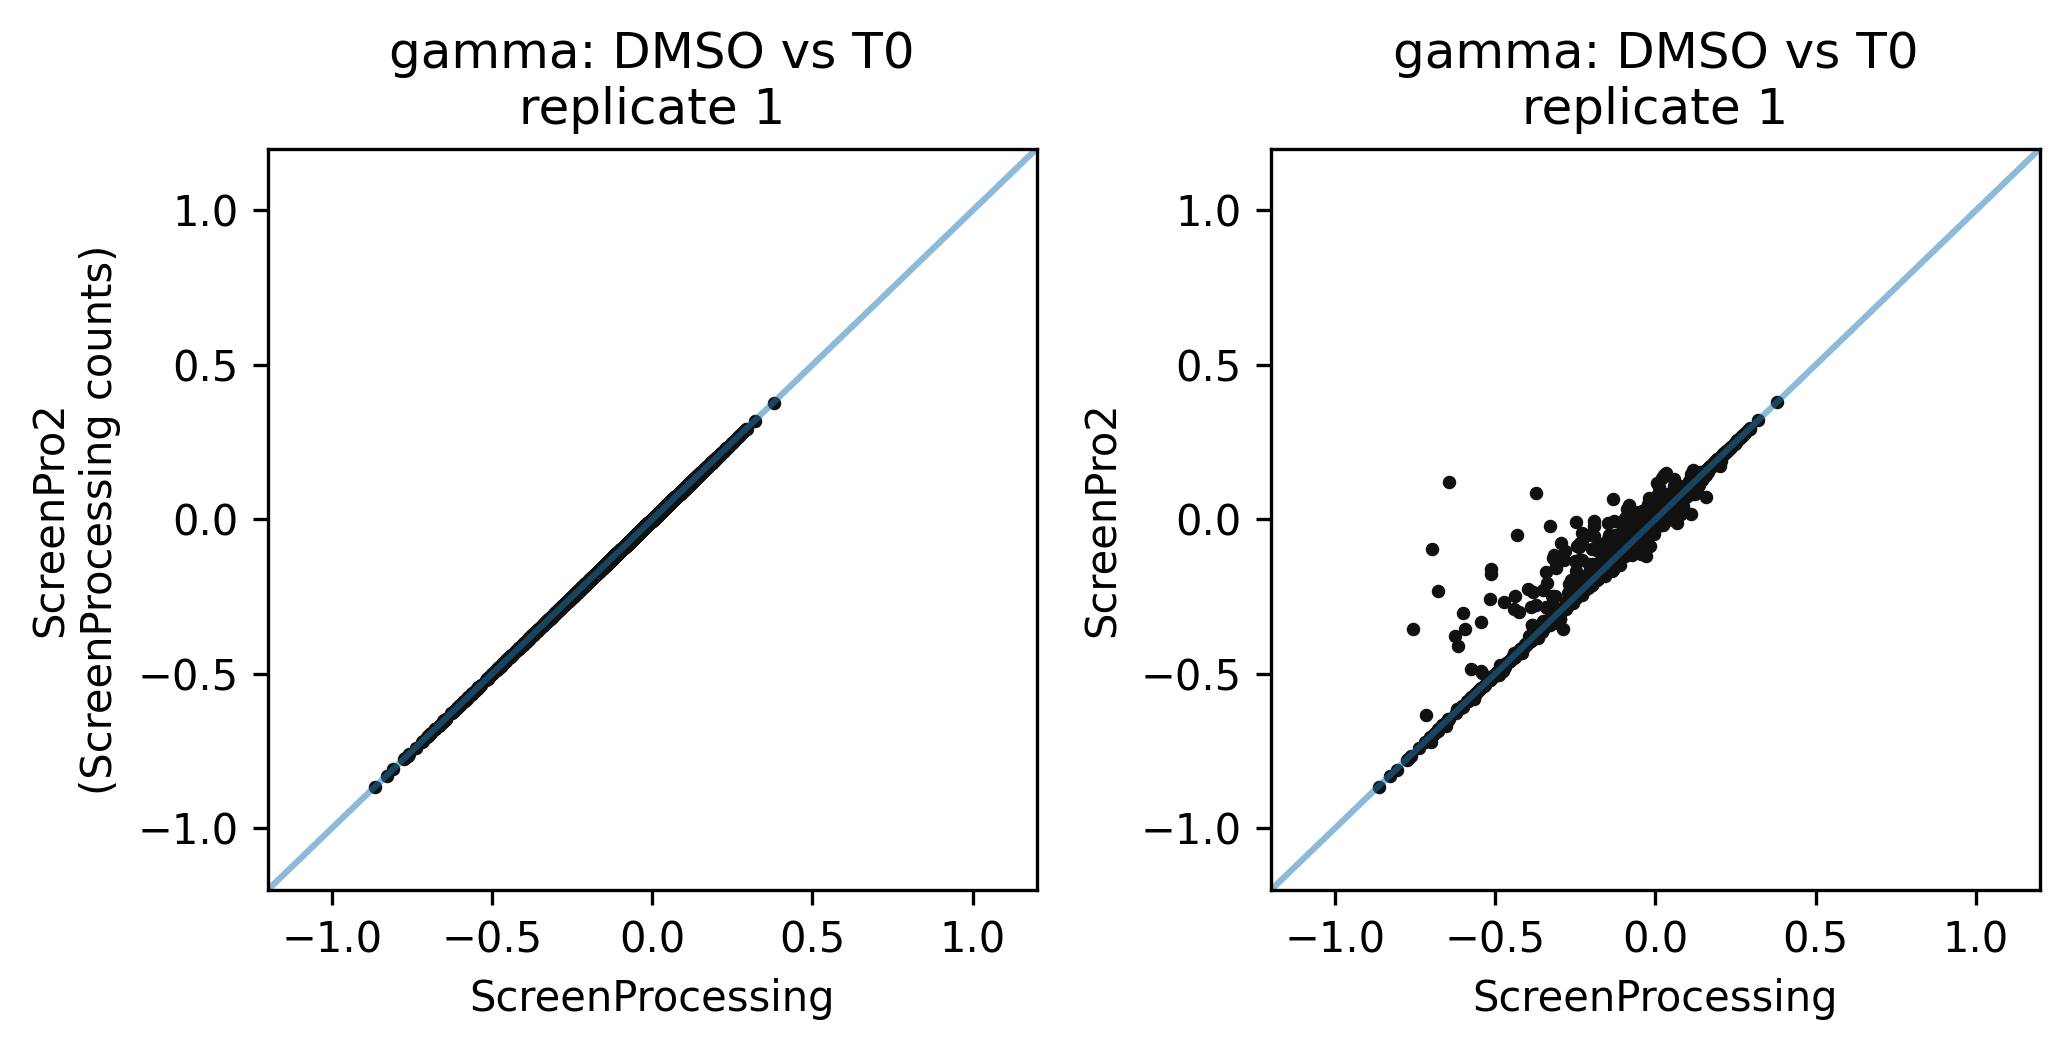

In [28]:
fig, axes = plt.subplots(1,2,figsize=(7,3.6), dpi=300)

# scatter_with_gaussian_kde(
#    ax=axes[0],
axes[0].scatter(
    x=d1[ol],
    y=d2[ol],
    s=5,
    color=scp.pl._utils.almost_black
)

axes[0].set_xlabel('ScreenProcessing')
axes[0].set_ylabel('ScreenPro2\n(ScreenProcessing counts)')
axes[0].set_title('gamma: DMSO vs T0\nreplicate 1')

# scatter_with_gaussian_kde(
#     ax=axes[1],
axes[1].scatter(
    x=d1[ol],
    y=d3[ol],
    s=5,
    color=scp.pl._utils.almost_black
)

axes[1].set_xlabel('ScreenProcessing')
axes[1].set_ylabel('ScreenPro2')

axes[1].set_title('gamma: DMSO vs T0\nreplicate 1')

for ax in axes: 
    ax.axline((0, 0), slope=1, alpha=.5)
    ax.set_xlim(-1.2,1.2)
    ax.set_ylim(-1.2,1.2)
    
    ax.set_xticks(np.linspace(-1,1,5))
    ax.set_yticks(np.linspace(-1,1,5))

plt.tight_layout()
plt.show()

---

In [29]:
d1 = molm13_screenprocessing.phenotypes['transcriptTable'
]['results']['gamma:DMSO_vs_T0'].dropna().query('~index.duplicated()')['average phenotype of strongest 3']

d2 = molm13_screenprocessing.phenotypes[
    # 'compare_guides_all' 
    'compare_guides_top_3'
]['results']['gamma:DMSO_vs_T0'].dropna().query('~index.duplicated()').sort_values(
    ['target','ttest pvalue']
)['score']

d3 = molm13_screen.phenotypes[
    # 'compare_guides_all' 
    'compare_guides_top_3'
]['results']['gamma:DMSO_vs_T0'].dropna().query('~index.duplicated()').sort_values(
    ['target','ttest pvalue']
)['score']

ol = list(set(d1.index) & set(d2.index) & set(d3.index))
ol = [t for t in ol if 'pseudo' not in t]
ol.sort()

In [30]:
len(ol)

2019

___

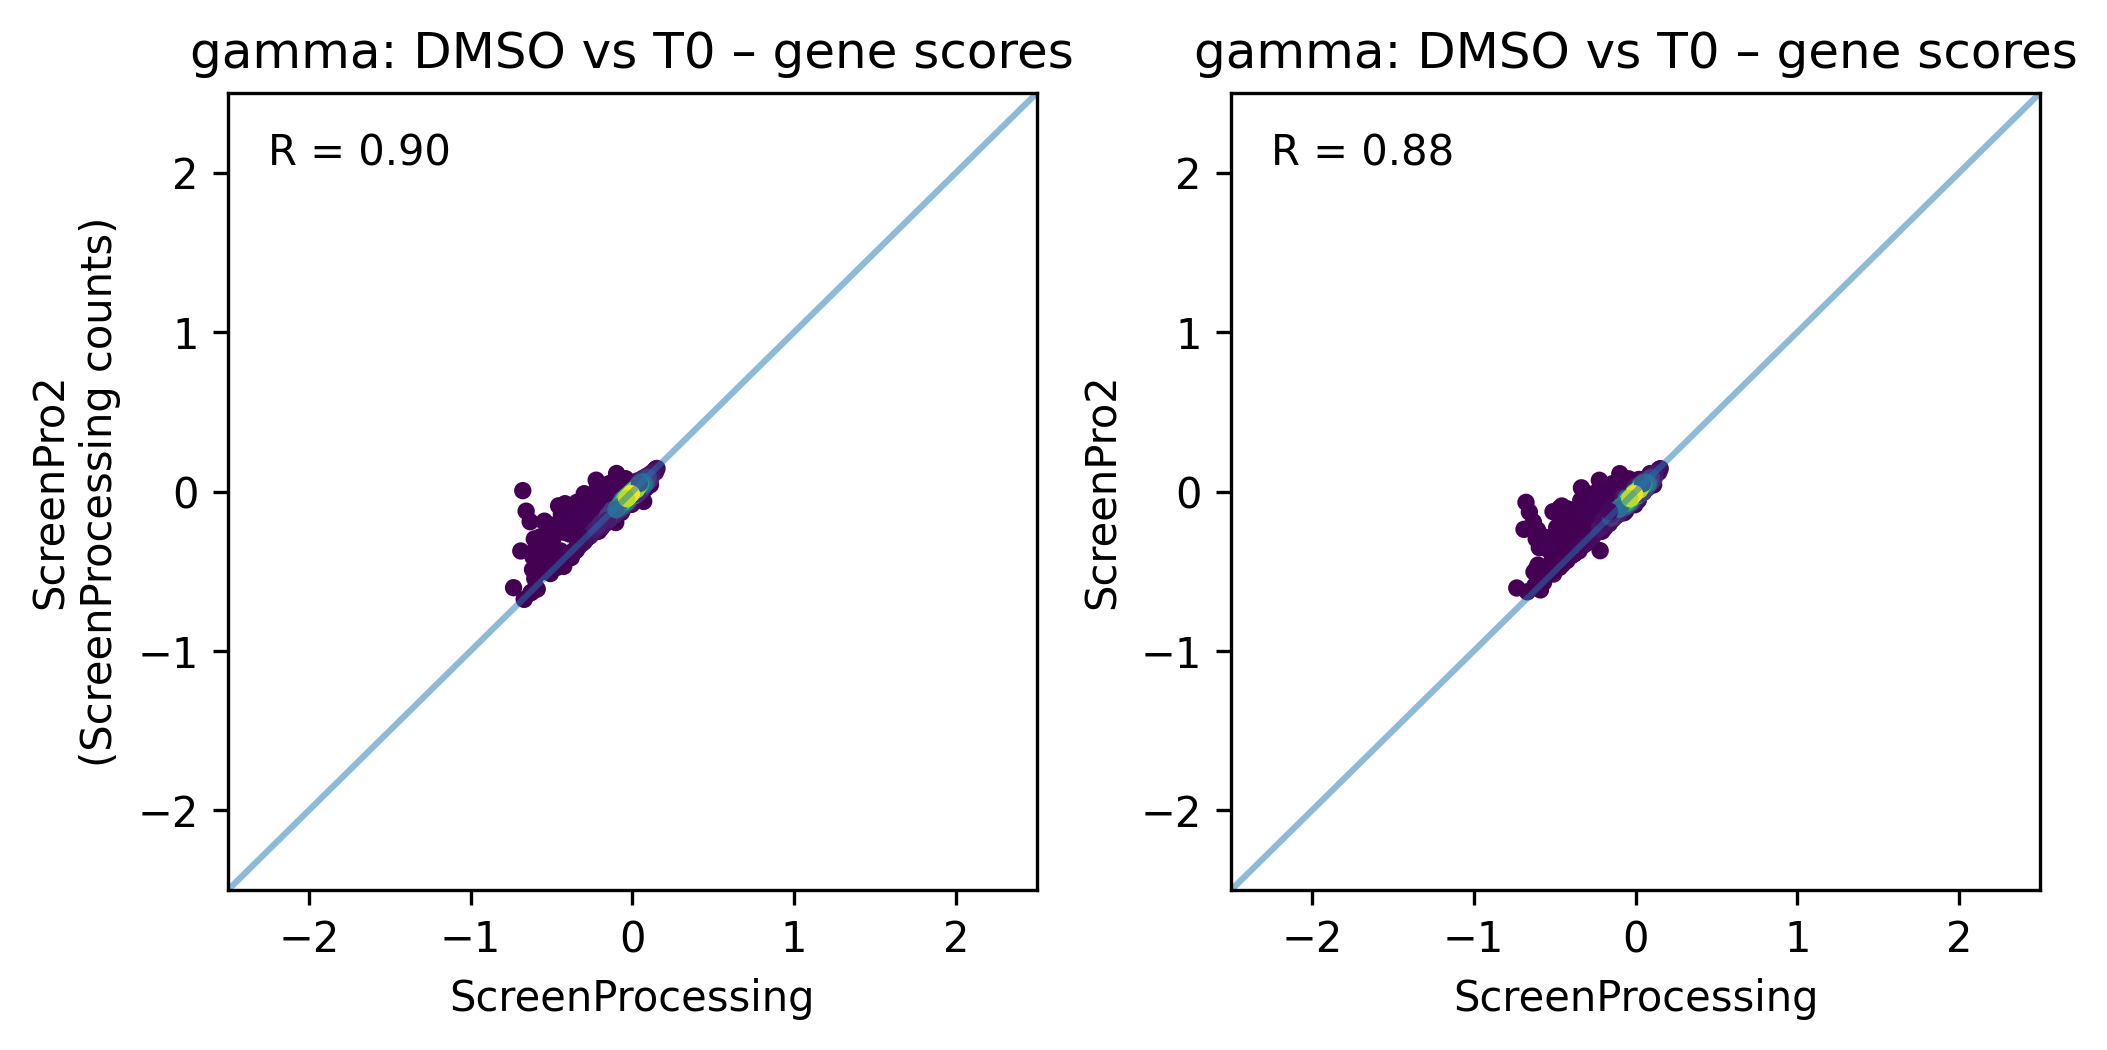

In [31]:
fig, axes = plt.subplots(1,2,figsize=(7,3.6), dpi=300)

scatter_with_gaussian_kde(
    ax=axes[0],
    x=d1[ol],
    y=d2[ol],
)

axes[0].set_xlabel('ScreenProcessing')
axes[0].set_ylabel('ScreenPro2\n(ScreenProcessing counts)')
axes[0].set_title('gamma: DMSO vs T0 – gene scores',fontsize=12)

# axes[1].set_visible(False)

scatter_with_gaussian_kde(
    ax=axes[1],
    x=d1[ol],
    y=d3[ol],
)

axes[1].set_xlabel('ScreenProcessing')
axes[1].set_ylabel('ScreenPro2')
axes[1].set_title('gamma: DMSO vs T0 – gene scores',fontsize=12)

for ax in axes: 
    ax.axline((0, 0), slope=1, alpha=.5)
    ax.set_xlim(-2.5,2.5)
    ax.set_ylim(-2.5,2.5)
    
    # ax.set_xticks(np.linspace(-2,2,5))
    # ax.set_yticks(np.linspace(-2,2,5))

plt.tight_layout()
plt.show()

In [32]:
# sanity check: see example genes in the dataframes
# that a negative score in ScreenProcessing corresponds 
# to a positve score in ScreenPro2 as non-expected outcome

pd.concat({
    'ScreenProcessing': d1[ol], # ScreenProcessing gene scores for rho: DAC vs DMSO
    'ScreenPro2': d2[ol], # ScreenPro2 gene scores for rho: DAC vs DMSO (ScreenProcessing counts)
},axis=1).query('ScreenProcessing > -.09 and ScreenPro2 < -0.1')

,ScreenProcessing,ScreenPro2
ASNSD1-P1P2,-0.080875,-0.119303
BBS5-P1P2,-0.088050,-0.139285
C17orf51-P1,-0.074538,-0.113981
C19orf45-P1,-0.068613,-0.130349
C2orf69-P1P2,-0.085750,-0.138058
CDK2AP2-P1P2,-0.068233,-0.129931
CLEC16A-P1P2,-0.081392,-0.106954
CMTM5-P1P2,-0.088962,-0.105689
CSAG3-ENST00000356911.4,-0.080442,-0.110489
GDNF-AS1-ENST00000514532.2,-0.077175,-0.104586


In [33]:
col = 'CDCA3'

In [34]:
molm13_screenprocessing_counts[
    molm13_screenprocessing_counts.index.str.contains(col)
].sort_values(by='DMSO_Rep1', ascending=False)

,DAC_Rep1,DAC_Rep2,DMSO_Rep1,DMSO_Rep2,T0_Rep1,T0_Rep2
sgId,,,,,,
CDCA3_+_6960400.23-P1P2,24,92,367,290,153,183
CDCA3_-_6961262.23-P1P2,43,113,290,91,77,77
CDCA3_+_6960198.23-P1P2,190,35,50,101,226,287
CDCA3_+_6961072.23-P1P2,35,0,5,12,221,287
CDCA3_-_6961161.23-P1P2,0,9,1,7,103,123


In [35]:
molm13_screenprocessing_counts[
    molm13_screenprocessing_counts.index.str.contains(col)
].sort_values(by='DMSO_Rep1', ascending=False).apply(
    # search for DAC prefix, then DMSO prefix, and return the ratio of sum of DAC counts to sum of DMSO counts
    lambda x: np.log2((x.filter(regex='^DMSO').sum() + 1) / (x.filter(regex='^T0').sum() + 1)), axis=1
)

sgId
CDCA3_+_6960400.23-P1P2    0.965339
CDCA3_-_6961262.23-P1P2    1.301304
CDCA3_+_6960198.23-P1P2   -1.757697
CDCA3_+_6961072.23-P1P2   -4.821597
CDCA3_-_6961161.23-P1P2   -4.656623
dtype: float64

What can I conclude from the comparison of guide level scores between ScreenProcessing and ScreenPro2?!

## Evaluation metrics

### AUC-ROC
CommonEssentials

In [36]:
from sklearn import metrics
from sklearn.metrics import precision_recall_curve
import matplotlib.lines as mlines

In [37]:
# from screenpro.phenoscore.evaluate import calcPR, calcROC

import numpy as np
from sklearn import metrics
from sklearn.metrics import precision_recall_curve
import matplotlib.lines as mlines


def calcROC(df_in, essential, nonessential, score_col, target_col='target', verbose=False):
    df = df_in.copy()
    # df[target_col] = df[target_col].str.split('-').str[0]
    
    # AUC-ROC
    df['DepMap'] = [
        'essential' if target in essential else 
        'non_essential' if target in nonessential else 
        np.nan for target in df[target_col]
    ]

    y_true = df[df['DepMap'].notna()]['DepMap']
    y_scores = df[df['DepMap'].notna()][score_col]
    
    fpr, tpr, thresholds = metrics.roc_curve(y_true, y_scores, pos_label='non_essential')
    
    if verbose: print('ROC-AUC score:', metrics.roc_auc_score(y_true, y_scores))
    
    return fpr, tpr


def calcPR(df_in, truePos, trueNeg, score_col, target_col='target', ascending=True, verbose=False):

    df = df_in.copy()

    scoreList = df.set_index(target_col)[score_col]

    truePos = truePos.intersection(scoreList.index)
    trueNeg = trueNeg.intersection(scoreList.index)
    
    cumulativeTup = [(0,1,np.nan)]
    cumulativeTP = 0.0
    cumulativeFP = 0.0
    
    tup_cross95 = None
    
    for gene, fold_change in scoreList.sort_values(inplace=False, ascending=ascending).items():
        if gene in truePos or gene in trueNeg:
            if gene in truePos:
                cumulativeTP += 1

            elif gene in trueNeg:
                cumulativeFP += 1

            cumulativeTup.append((cumulativeTP / len(truePos), cumulativeTP / (cumulativeTP + cumulativeFP), fold_change))
    
    tup_cross95 = [cross95 for cross95 in cumulativeTup[::-1] if cross95[1] >= 0.95][0]
    
    if verbose: print('Precision-Recall AUC:', tup_cross95)
    
    return cumulativeTup, tup_cross95


In [38]:
DepMap_essential = pd.read_csv(
    '/home/abe/tools/CanDI/CanDI/setup/data/depmap/21Q4/common_essentials.csv', sep=' '
).index.to_list()
DepMap_essential = list(set(DepMap_essential) & \
                        set(library_table.query('gene != "negative_control"')['gene']))

DepMap_nonessential = pd.read_csv(
    '/home/abe/tools/CanDI/CanDI/setup/data/depmap/21Q4/nonessentials.csv', sep=' '
).index.to_list()

DepMap_nonessential = list(set(DepMap_nonessential) & \
                           set(library_table.query('gene != "negative_control"')['gene']))


___

In [39]:
gamma_screenprocessing = molm13_screenprocessing.phenotypes['geneTable']['results']['gamma:DMSO_vs_T0']

gamma_screenprocessing = scp.ps.annotateScoreTable(
    gamma_screenprocessing,
    up_hit=scp.ps._annotate.hit_dict['gamma']['up_hit'],
    down_hit=scp.ps._annotate.hit_dict['gamma']['down_hit'],
    ctrl_label='negative_control',
    score_col='average phenotype of strongest 3',
    pvalue_col='Mann-Whitney p-value',
    threshold=1
)

gamma_screenprocessing.dropna(inplace=True)

gamma_screenprocessing = gamma_screenprocessing.query(
    'target != "negative_control"')

In [40]:
gamma_screenpro2 = molm13_screen.phenotypes['compare_guides_top_3']['results']['gamma:DMSO_vs_T0']

gamma_screenpro2 = scp.ps.annotateScoreTable(
    gamma_screenpro2,
    up_hit=scp.ps._annotate.hit_dict['rho']['up_hit'],
    down_hit=scp.ps._annotate.hit_dict['rho']['down_hit'],
    ctrl_label='negative_control',
    pvalue_col='ttest pvalue',
    threshold=1
)

gamma_screenpro2.dropna(inplace=True)

gamma_screenpro2 = gamma_screenpro2.query('target != "negative_control"')

In [41]:
gamma_screenpro2_with_screenprocessing_counts = molm13_screenprocessing.phenotypes['compare_guides_top_3']['results']['gamma:DMSO_vs_T0']

gamma_screenpro2_with_screenprocessing_counts = scp.ps.annotateScoreTable(
    gamma_screenpro2_with_screenprocessing_counts,
    up_hit=scp.ps._annotate.hit_dict['rho']['up_hit'],
    down_hit=scp.ps._annotate.hit_dict['rho']['down_hit'],
    ctrl_label='negative_control',
    pvalue_col='ttest pvalue',
    threshold=1
)
gamma_screenpro2_with_screenprocessing_counts.dropna(inplace=True)

gamma_screenpro2_with_screenprocessing_counts = gamma_screenpro2_with_screenprocessing_counts.query('target != "negative_control"')

In [42]:
# gamma_pyDESeq2_with_screenprocessing_counts = molm13_screenprocessing.phenotypes['pyDESeq2']['results']['gamma:DMSO_vs_T0']

# gamma_pyDESeq2_with_screenprocessing_counts = scp.ps.annotateScoreTable(
#     gamma_pyDESeq2_with_screenprocessing_counts,
#     up_hit=scp.ps._annotate.hit_dict['rho']['up_hit'],
#     down_hit=scp.ps._annotate.hit_dict['rho']['down_hit'],
#     ctrl_label='negative_control',
#     score_col='log2FoldChange',
#     pvalue_col='pvalue',
#     threshold=1
# )

# gamma_pyDESeq2_with_screenprocessing_counts = gamma_pyDESeq2_with_screenprocessing_counts.sort_values('pvalue').drop_duplicates('target',keep='first')

# gamma_pyDESeq2_with_screenprocessing_counts.dropna(inplace=True)

# gamma_pyDESeq2_with_screenprocessing_counts = gamma_pyDESeq2_with_screenprocessing_counts.query('target != "negative_control"')

___

In [43]:
ol = list(
    set(gamma_screenpro2['target']) & \
    set(gamma_screenprocessing['target']) & \
    set(gamma_screenpro2_with_screenprocessing_counts['target'])
)

In [44]:
df = gamma_screenprocessing.query(f'target in {ol}').copy()
target_col = 'average phenotype of strongest 3'
essential=DepMap_essential
nonessential=DepMap_nonessential


# df[target_col] = df[target_col].str.split('-').str[0]
# df[target_col]
# # AUC-ROC
df['DepMap'] = ['essential' if target in essential else 'non_essential' if target in nonessential else np.nan for target in df[target_col]]

In [45]:
gamma_screenprocessing_fpr, gamma_screenprocessing_tpr = calcROC(
    gamma_screenprocessing.query(f'target in {ol}'),
    score_col = 'average phenotype of strongest 3',
    # score_col = 'Mann-Whitney p-value',
    # score_col = 'combined_score'
    essential=DepMap_essential,
    nonessential=DepMap_nonessential
)

In [46]:
gamma_screenpro2_fpr, gamma_screenpro2_tpr = calcROC(
    gamma_screenpro2.query(f'target in {ol}'), 
    # score_col = 'ttest pvalue'
    score_col = 'score',
    # score_col = 'combined_score'
    essential=DepMap_essential,
    nonessential=DepMap_nonessential
)

In [47]:
gamma_screenpro2_with_screenprocessing_counts_fpr, gamma_screenpro2_with_screenprocessing_counts_tpr = calcROC(
    gamma_screenpro2_with_screenprocessing_counts.query(f'target in {ol}'), 
    # score_col = 'ttest pvalue'
    score_col = 'score',
    # score_col = 'combined_score'
    essential=DepMap_essential,
    nonessential=DepMap_nonessential
)

In [48]:
# gamma_pyDESeq2_with_screenprocessing_counts_fpr, gamma_pyDESeq2_with_screenprocessing_counts_tpr = calcROC(
#     gamma_pyDESeq2_with_screenprocessing_counts.query(f'target in {ol}'), 
#     score_col = 'log2FoldChange'
#     # score_col = 'combined_score'
# )

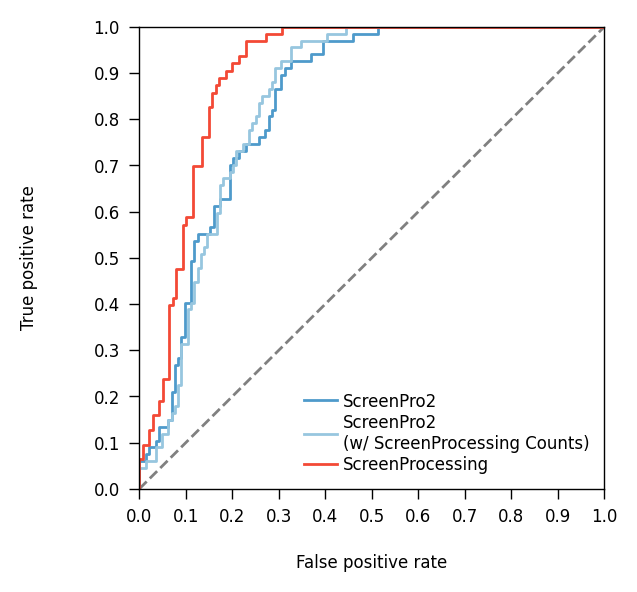

In [49]:
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)

#colors = iter(['#8dd8ce', '#bfbfbf', '#ffcc66', '#a7e382'])
colors = iter([plt.cm.Blues(150), plt.cm.Blues(100), plt.cm.Reds(150), plt.cm.Reds(100)])

plt.plot(
    gamma_screenpro2_fpr, 
    gamma_screenpro2_tpr, 
    label='ScreenPro2', color=next(colors), linewidth=1
)
plt.plot(
    gamma_screenpro2_with_screenprocessing_counts_fpr, 
    gamma_screenpro2_with_screenprocessing_counts_tpr, 
    label='ScreenPro2\n(w/ ScreenProcessing Counts)',
    color=next(colors), linewidth=1
)

# plt.plot(
#     gamma_pyDESeq2_with_screenprocessing_counts_fpr, 
#     gamma_pyDESeq2_with_screenprocessing_counts_tpr, 
#     label='pyDESeq2\n(w/ ScreenProcessing Counts)',
#     color=next(colors), linewidth=1
# )

plt.plot(
    gamma_screenprocessing_fpr, 
    gamma_screenprocessing_tpr, 
    label='ScreenProcessing', color=next(colors), linewidth=1
)

line = mlines.Line2D([0, 100], [0, 100], color='grey', linestyle='--', linewidth = 1, zorder=0)
transform = ax.transAxes
line.set_transform(transform)
ax.add_line(line)

min_val = 0
max_val = 1

plt.ylim(bottom= min_val, top=max_val)
plt.xlim(left= min_val, right=max_val)

# plt.gca().spines['right'].set_color('none')
# plt.gca().spines['top'].set_color('none')
#plt.title('DepMap', fontsize=14, pad=10) #21Q1
plt.xlabel('False positive rate', fontsize=12, labelpad=10)
plt.ylabel('True positive rate', fontsize=12, labelpad=20)
plt.xticks(np.arange(0,1.2,0.2))
plt.tick_params(labelsize=24, bottom=True, left=True)
plt.xticks(np.linspace(0,1,11))
plt.yticks(np.linspace(0,1,11))

plt.legend(
    ncol=1, fontsize=6, frameon=False, 
    handletextpad=0.35, labelspacing=0.20, title='', title_fontsize=12,
    loc='lower right'
) #AUC = 0.95-0.89

for axis in ['top','bottom','left','right']:
    ax.spines[axis].set_linewidth(.5)
ax.tick_params(width=.5)

for item in ([ax.title]):
    item.set_fontsize(8)
for item in ([ax.xaxis.label, ax.yaxis.label]):
    item.set_fontsize(6)
for item in ax.get_xticklabels() + ax.get_yticklabels():
    item.set_fontsize(6)

#plt.savefig('/home/tdfair/Desktop/ROC.pdf', bbox_inches='tight', dpi=750)
plt.show()

Precision-Recall

In [50]:
gamma_screenprocessing_cumulativeTup, gamma_screenprocessing_tup_cross95 = calcPR(
    gamma_screenprocessing,
    # gamma_screenprocessing[''], 
    truePos=set(DepMap_essential), 
    trueNeg=set(DepMap_nonessential),
    score_col='average phenotype of strongest 3'
    # combined_score
    # 'Mann-Whitney p-value'
)

gamma_screenpro2_cumulativeTup, gamma_screenpro2_tup_cross95 = calcPR(
    gamma_screenpro2, 
    truePos=set(DepMap_essential), 
    trueNeg=set(DepMap_nonessential),
    score_col='score'
)

# gamma_pyDESeq2_with_screenprocessing_counts_cumulativeTup, gamma_pyDESeq2_with_screenprocessing_counts_tup_cross95 = calcPR(
#     gamma_pyDESeq2_with_screenprocessing_counts['log2FoldChange'], 
#     # gamma_screenpro2_with_screenprocessing_counts['ttest pvalue'], 
#     set(DepMap_essential), set(DepMap_nonessential))

gamma_screenpro2_with_screenprocessing_counts_cumulativeTup, gamma_screenpro2_with_screenprocessing_counts_tup_cross95 = calcPR(
    # gamma_screenpro2_with_screenprocessing_counts['ttest pvalue'], 
    gamma_screenpro2_with_screenprocessing_counts,
    # gamma_screenpro2_with_screenprocessing_counts['combined_score'], 
    truePos=set(DepMap_essential), 
    trueNeg=set(DepMap_nonessential),
    score_col='score'
)

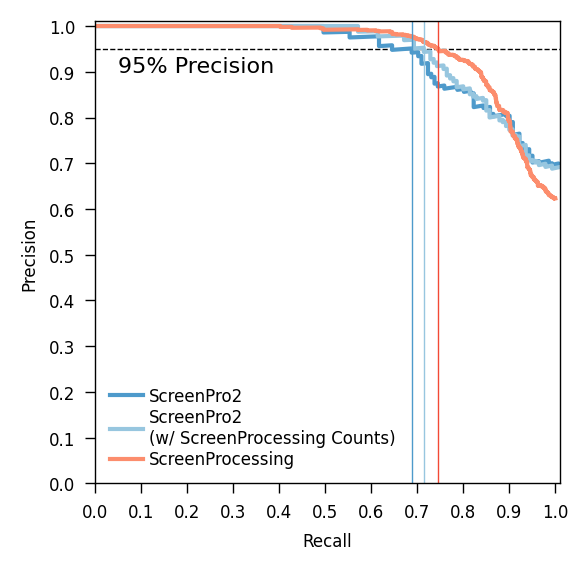

In [51]:
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)

colors = [plt.cm.Blues(150), plt.cm.Blues(100), plt.cm.Reds(150), plt.cm.Reds(100)]

plt.plot([recall[0] for recall in gamma_screenpro2_cumulativeTup], 
         [precision[1] for precision in gamma_screenpro2_cumulativeTup], label='ScreenPro2', c=colors[0])

plt.plot([recall[0] for recall in gamma_screenpro2_with_screenprocessing_counts_cumulativeTup], 
         [precision[1] for precision in gamma_screenpro2_with_screenprocessing_counts_cumulativeTup], 
         label='ScreenPro2\n(w/ ScreenProcessing Counts)',
         # label='ScreenPro2', 
         c=colors[1])

# plt.plot([recall[0] for recall in gamma_pyDESeq2_with_screenprocessing_counts_cumulativeTup], 
#          [precision[1] for precision in gamma_pyDESeq2_with_screenprocessing_counts_cumulativeTup], 
#          label='pyDESeq2', c=colors[2])

plt.plot([recall[0] for recall in gamma_screenprocessing_cumulativeTup], 
         [precision[1] for precision in gamma_screenprocessing_cumulativeTup], 
         label='ScreenProcessing', 
         c=colors[3])

plt.axvline(gamma_screenpro2_tup_cross95[0], lw=.5, c=colors[0])
plt.axvline(gamma_screenpro2_with_screenprocessing_counts_tup_cross95[0], lw=.5, c=colors[1])
plt.axvline(gamma_screenprocessing_tup_cross95[0], lw=.5, c=colors[2])

for item in ([ax.title]):
    item.set_fontsize(8)
for item in ([ax.xaxis.label, ax.yaxis.label]):
    item.set_fontsize(6)
for item in ax.get_xticklabels() + ax.get_yticklabels():
    item.set_fontsize(6)

for axis in ['top','bottom','left','right']:
    ax.spines[axis].set_linewidth(.5)
ax.tick_params(width=.5)

plt.xlim(0,1.01)
plt.ylim(0,1.01)
plt.xticks(np.linspace(0,1,11))
plt.yticks(np.linspace(0,1,11))
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.axhline(0.95, c='black', lw=0.5, ls='--', zorder=0)
plt.text(0.05, 0.9, '95% Precision', fontsize=8)

plt.legend(
    ncol=1, fontsize=6, frameon=False,
    handletextpad=0.35, labelspacing=0.20, title='', title_fontsize=12,
    loc='lower left'
)

plt.tick_params(bottom=True, left=True)

#plt.savefig('/home/tyler/Desktop/PR_curve_hCRISPRi-v2.png', bbox_inches='tight', dpi=300)
plt.show()

---

In [52]:
# fig, ax1 = plt.subplots(1,1,figsize=(3,4))

# ## draw venn diagram
# n_top_hits = 100

# # resistance_hit
# venn(
#     {
#         'CommonEssentials':set(DepMap_essential),
#         'CommonNonEssentials':set(DepMap_nonessential),
#         'ScreenProcessing Essentials':set(gamma_screenprocessing['target'].to_list()),
#     }, ax=ax1,
#     # legend_loc=None
# )

# # plt.title('Sensitivity hits', fontsize=22)
# plt.show()

### Compare scores

In [53]:
rho_screenprocessing = molm13_screenprocessing.phenotypes['geneTable']['results']['rho:DAC_vs_DMSO']

rho_screenprocessing = scp.ps.annotateScoreTable(
    rho_screenprocessing,
    up_hit=scp.ps._annotate.hit_dict['rho']['up_hit'],
    down_hit=scp.ps._annotate.hit_dict['rho']['down_hit'],
    ctrl_label='negative_control',
    score_col='average phenotype of strongest 3',
    pvalue_col='Mann-Whitney p-value',
    threshold=5
)

rho_screenprocessing = rho_screenprocessing.query('target != "negative_control"')

In [54]:
rho_screenprocessing.groupby('label').size()

label
sensitivity_hit      128
resistance_hit       117
target_non_hit     18660
dtype: int64

In [55]:
rho_screenpro2 = molm13_screen.phenotypes['compare_guides_top_3']['results']['rho:DAC_vs_DMSO']

rho_screenpro2 = scp.ps.annotateScoreTable(
    rho_screenpro2,
    up_hit=scp.ps._annotate.hit_dict['rho']['up_hit'],
    down_hit=scp.ps._annotate.hit_dict['rho']['down_hit'],
    ctrl_label='negative_control',
    pvalue_col='ttest pvalue',
    threshold=2
)

rho_screenpro2 = rho_screenpro2.query('target != "negative_control"')


In [56]:
rho_screenpro2_with_screenprocessing_counts = molm13_screenprocessing.phenotypes['compare_guides_top_3']['results']['rho:DAC_vs_DMSO']

rho_screenpro2_with_screenprocessing_counts = scp.ps.annotateScoreTable(
    rho_screenpro2_with_screenprocessing_counts,
    up_hit=scp.ps._annotate.hit_dict['rho']['up_hit'],
    down_hit=scp.ps._annotate.hit_dict['rho']['down_hit'],
    ctrl_label='negative_control',
    pvalue_col='ttest pvalue',
    threshold=2
)

rho_screenpro2_with_screenprocessing_counts = rho_screenpro2_with_screenprocessing_counts.query('target != "negative_control"')

In [57]:
rho_screenpro2.groupby('label').size()

label
sensitivity_hit     111
resistance_hit      113
target_non_hit     1797
dtype: int64

In [58]:
rho_screenpro2_with_screenprocessing_counts.groupby('label').size()

label
sensitivity_hit     122
resistance_hit      110
target_non_hit     1788
dtype: int64

- check 200 hits from screenprocessing 

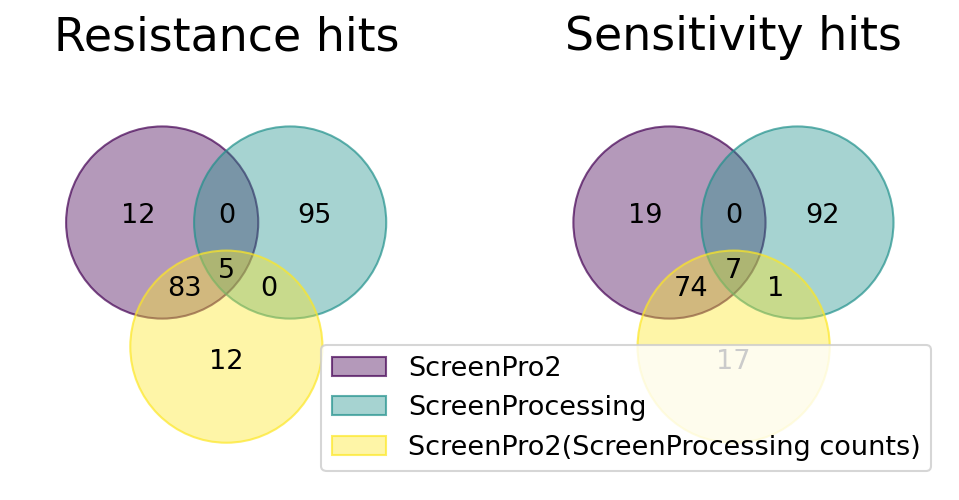

In [59]:
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(8,4), dpi=150)

## draw venn diagram
n_top_hits = 100

# resistance_hit
venn({
    'ScreenPro2':set(rho_screenpro2.dropna().sort_values('combined_score').tail(n_top_hits)['target'].to_list()),
    'ScreenProcessing':set(rho_screenprocessing.dropna().sort_values('combined_score').tail(n_top_hits)['target'].to_list()),
    'ScreenPro2(ScreenProcessing counts)':set(rho_screenpro2_with_screenprocessing_counts.dropna().sort_values('combined_score').tail(n_top_hits)['target'].to_list()),
}, ax=ax1, legend_loc=None)

ax1.set_title('Resistance hits', fontsize=22)

# sensitivity_hits
venn({
    'ScreenPro2':set(rho_screenpro2.dropna().sort_values('combined_score').head(n_top_hits)['target'].to_list()),
    'ScreenProcessing':set(rho_screenprocessing.dropna().sort_values('combined_score').head(n_top_hits)['target'].to_list()),
    'ScreenPro2(ScreenProcessing counts)':set(rho_screenpro2_with_screenprocessing_counts.dropna().sort_values('combined_score').head(n_top_hits)['target'].to_list()),
}, ax=ax2, legend_loc='lower right')

ax2.set_title('Sensitivity hits', fontsize=22)

plt.title('Sensitivity hits', fontsize=22)
plt.show()

In [60]:
def draw_rank_plot(df, col, ax, name_hits, pos_hits, neg_hits, q_thr=0.05):
    
    _, _ = scp.pl._rank.rank_plot(
        df,
        col,
        ylabel='',
        highlight_values_dict={
            '#3182bd': {
                'genes': neg_hits,
                'text': False
            },
            # 'black': {
            #     'genes': [
            #         g for g in p53_targets 
            #         if g in df[sensitivity_hit | resistant_hit]['target'].to_list()
            #     ],
            #     'text': False
            # },
            'black': {
                'genes': name_hits,
                'text': True
            },
            '#de2d26': {
                'genes': pos_hits,
                'text': False
            },
            # 'darkblue': {
            #     'genes': ['CHD8', 'SOX9', 'ACTB','RNF4', 'VPS37A','MYBL2'],
            #     'text': True
            # },
        },
        ax=ax,
        highlight_size_factor=20,
        dot_size=.1,
        title=col
    )
    
    ax.set_xlim(-1000,21000)
    ax.tick_params(width=0.5)
    for i in ax.spines.values(): i.set_linewidth(0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # ax.spines['bottom'].set_visible(False)
    # ax.spines['left'].set_visible(False)
    for item in ([ax.title]):
        item.set_fontsize(8)
    for item in ([ax.xaxis.label, ax.yaxis.label]):
        item.set_fontsize(6)
    for item in ax.get_xticklabels() + ax.get_yticklabels():
        item.set_fontsize(6)
    
    # ax.hlines(df[col].quantile(q=q_thr), 0, 1, transform=ax.get_yaxis_transform(), linewidth=1, linestyles='-', colors='#3182bd')
    # ax.hlines(df[col].quantile(q=1-q_thr), 0, 1, transform=ax.get_yaxis_transform(), linewidth=1, linestyles='-', colors='#de2d26')

In [61]:
molm13_screenprocessing

In [62]:
rho_screenpro2[rho_screenpro2.sort_values('combined_score').target.str.contains('DCTD')]

/tmp/ipykernel_2769438/3111188005.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  rho_screenpro2[rho_screenpro2.sort_values('combined_score').target.str.contains('DCTD')]


,target,transcript,score,ttest pvalue,BH adj_pvalue,number_of_guide_elements,combined_score,label


In [63]:
molm13_screen

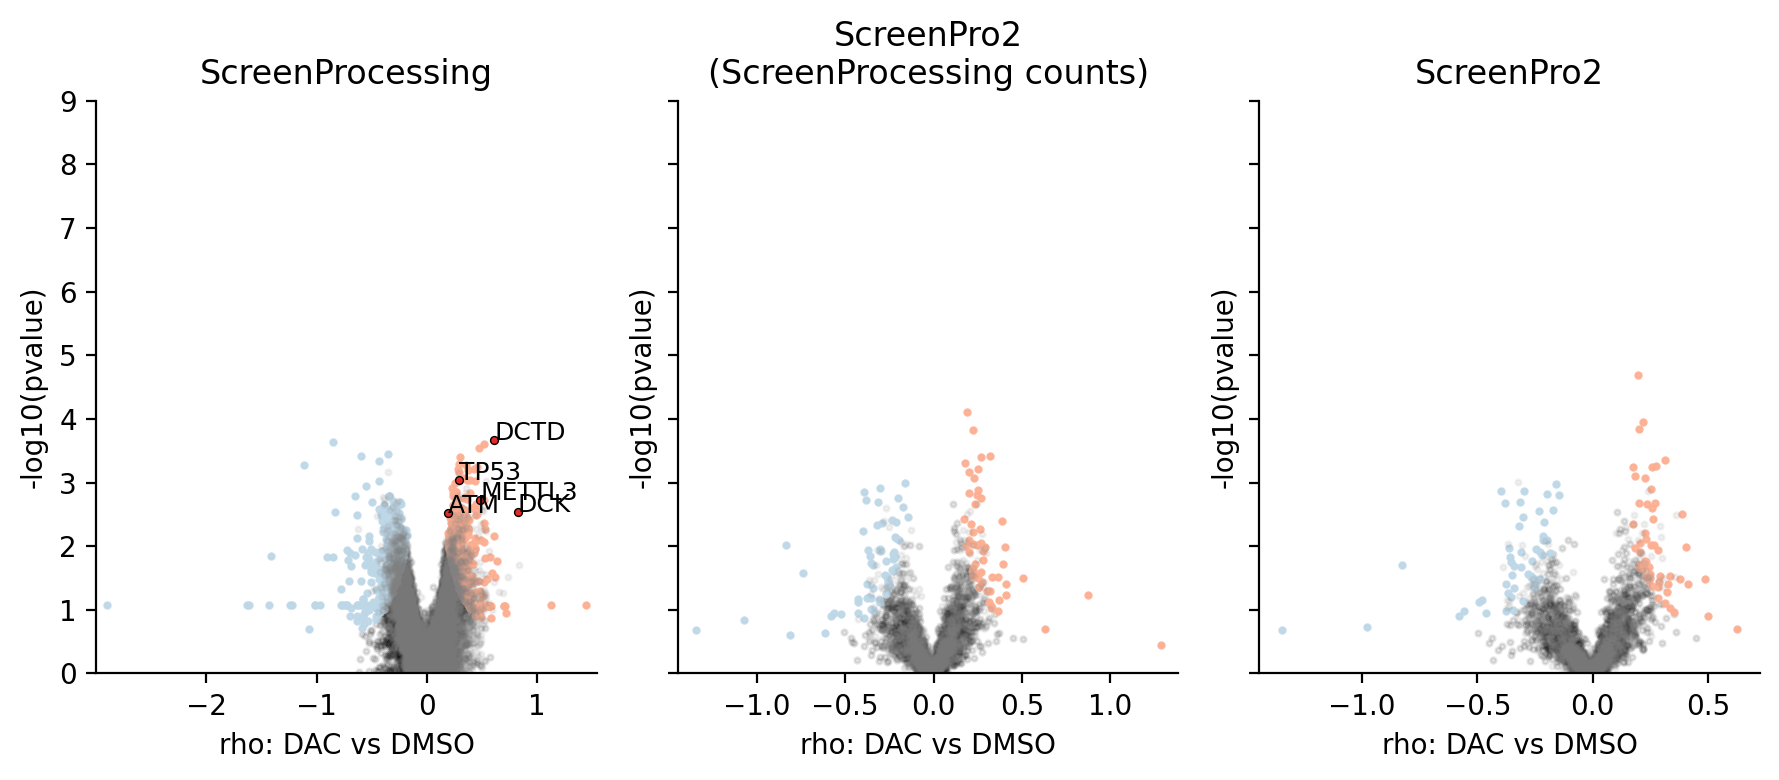

In [64]:
_, axes = plt.subplots(1,3,figsize=(9,4),dpi=200, sharey=True)


molm13_screenprocessing.drawVolcano(
    run_name='geneTable',
    phenotype_name='rho:DAC_vs_DMSO', 
    ax=axes[0], 
    score_col='average phenotype of strongest 3',
    pvalue_col='Mann-Whitney p-value', threshold=3,
    dot_size=4,
    resistance_hits=['DCK','DCTD','METTL3','TP53','ATM'],
    size_txt=9,
    t_x=0,
    t_y=0,
    ylims=[0,7],
    # xlims=[-3,2],
)
    
axes[0].set_title('ScreenProcessing')


molm13_screenprocessing.drawVolcano(
    run_name='compare_guides_top_3',
    phenotype_name='rho:DAC_vs_DMSO', 
    ax=axes[1], 
    pvalue_col='ttest pvalue', threshold=3,
    dot_size=4,
    resistance_hits=['DCK','DCTD','METTL3','TP53','ATM'],
    size_txt=9,
    ylims=[0,9],
    # xlims=[-3,3],
)

axes[1].set_title('ScreenPro2\n(ScreenProcessing counts)')


molm13_screen.drawVolcano(
    run_name='compare_guides_top_3',
    phenotype_name='rho:DAC_vs_DMSO', 
    ax=axes[2], 
    pvalue_col='ttest pvalue', threshold=3,
    dot_size=4,
    resistance_hits=['DCK','DCTD','METTL3','TP53','ATM'],
    size_txt=9,
    ylims=[0,9],
    # xlims=[-3,3],
    # x_
)

axes[2].set_title('ScreenPro2')


for ax in axes: 
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.get_legend().remove()

plt.tight_layout()
plt.show()

In [65]:
# dds = scp.ps.runDESeq(adata, 'condition')

In [66]:
# dds.var = adata.var.copy()

In [67]:
# _, ax = plt.subplots(1,1,figsize=(4,4),dpi=200)

# molm13_screen.drawVolcano(
#     run_name='pyDESeq2',
#     phenotype_name='rho:DAC_vs_DMSO', 
#     ax=ax,
#     score_col='log2FoldChange',
#     pvalue_col='pvalue', 
#     threshold=3,
#     dot_size=4,
#     resistance_hits=['DCK','DCTD','METTL3','TP53'],
#     size_txt=9,
#     # ylims=[0,9],
#     # xlims=[-3,3],
#     # x_
# )

___

/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/pandas/plotting/_matplotlib/core.py:1388: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = ax.scatter(
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/pandas/plotting/_matplotlib/core.py:1388: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = ax.scatter(
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/pandas/plotting/_matplotlib/core.py:1388: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = ax.scatter(


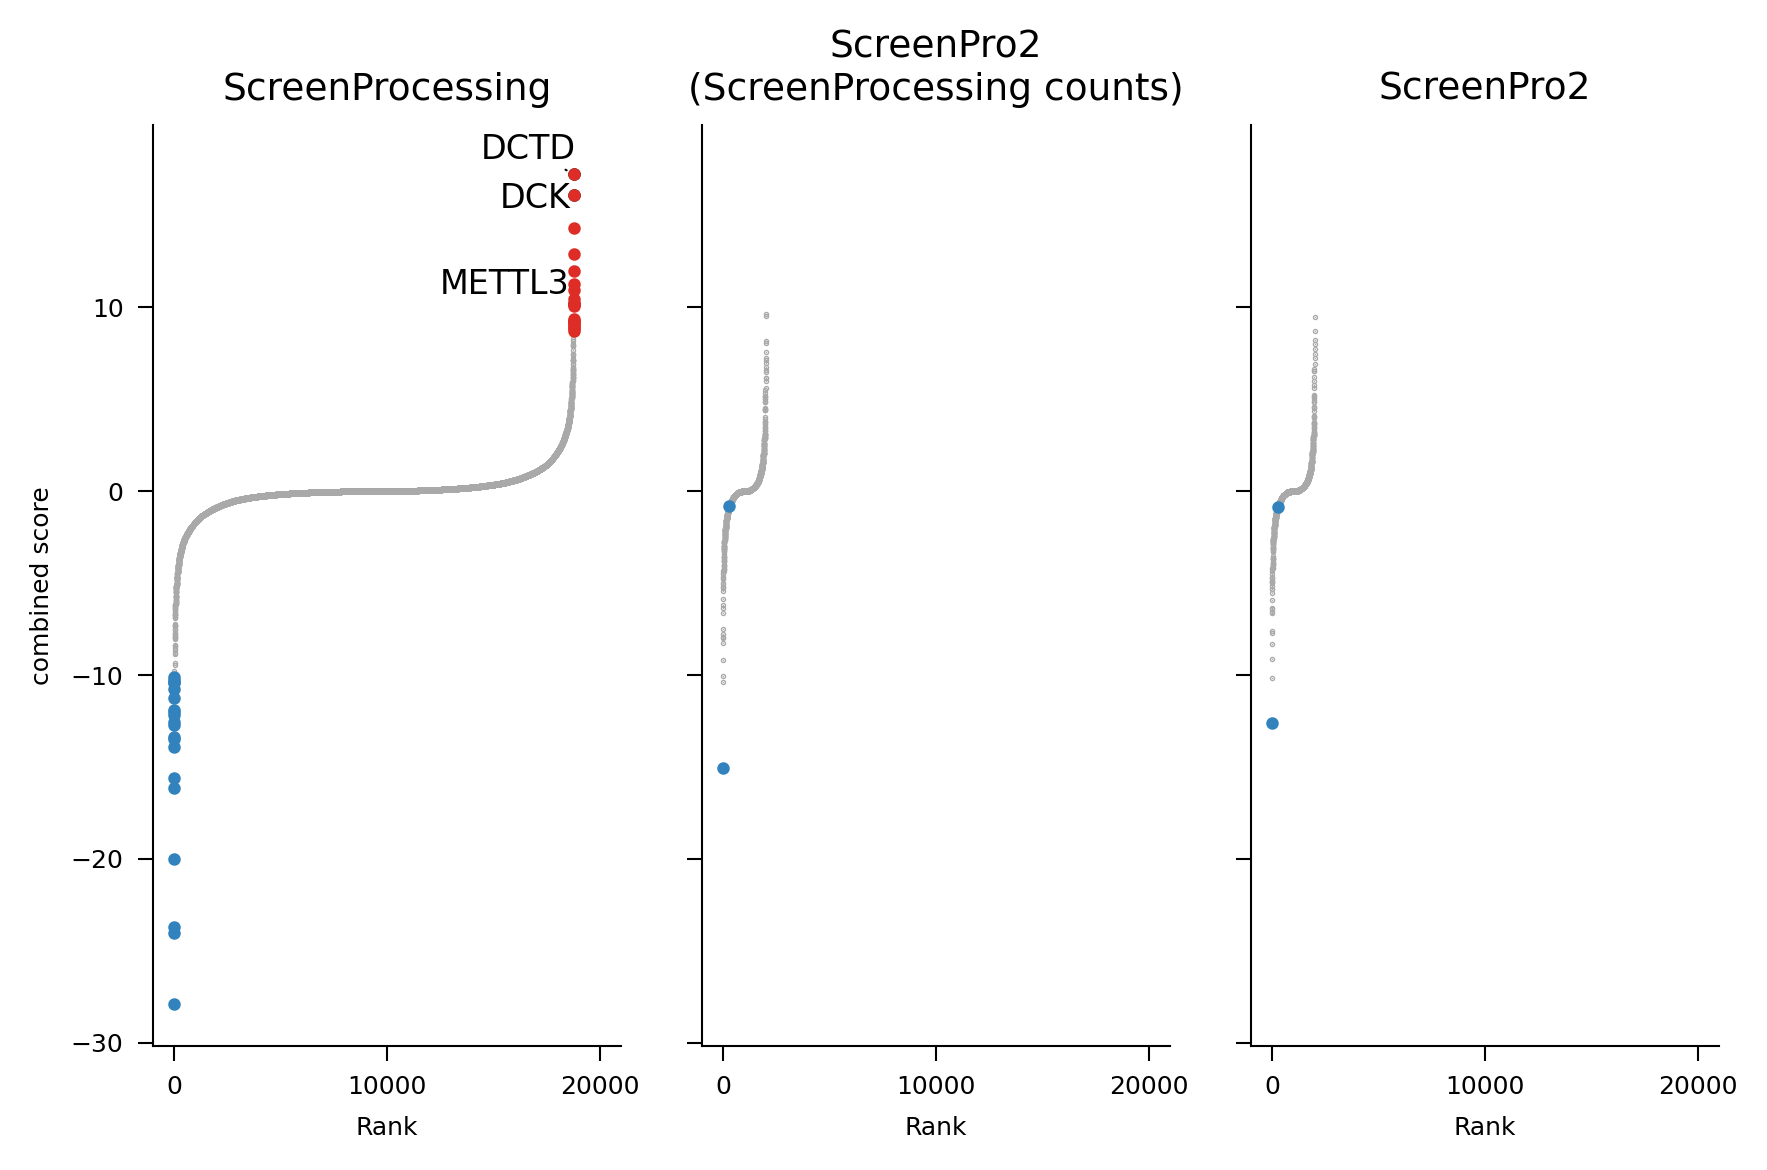

In [68]:
_, axes = plt.subplots(1,3,figsize=(6,4),sharey=True,dpi=300)

for ax, rho, title in zip(
    axes,
    [rho_screenprocessing,rho_screenpro2_with_screenprocessing_counts,rho_screenpro2],
    ['ScreenProcessing','ScreenPro2\n(ScreenProcessing counts)','ScreenPro2']
    ):
    draw_rank_plot(
        rho, 
        'combined_score',
        ax, 
        # q_thr=0.05,
        name_hits=['DCK','DCTD','METTL3'],
        pos_hits=rho_screenprocessing.query('target != "negative_control"').sort_values('combined_score').dropna().tail(20)['target'].to_list(),
        neg_hits=rho_screenprocessing.query('target != "negative_control"').sort_values('combined_score').dropna().head(20)['target'].to_list()
    )

    ax.set_title(title,fontsize=9)

axes[0].set_ylabel('combined score', fontsize=6)

# plt.title('ScreenPro2\nresults', fontsize=9)
plt.tight_layout()
plt.show()

## 

In [69]:
molm13_screen.buildPhenotypeData(run_name='compare_reps')

molm13_screen.pdata.obs['replicate'] = molm13_screen.pdata.obs.index.str[-1].astype(int)

In [70]:
molm13_screenprocessing.buildPhenotypeData(run_name='compare_reps')

molm13_screenprocessing.pdata.obs['replicate'] = molm13_screen.pdata.obs.index.str[-1].astype(int)

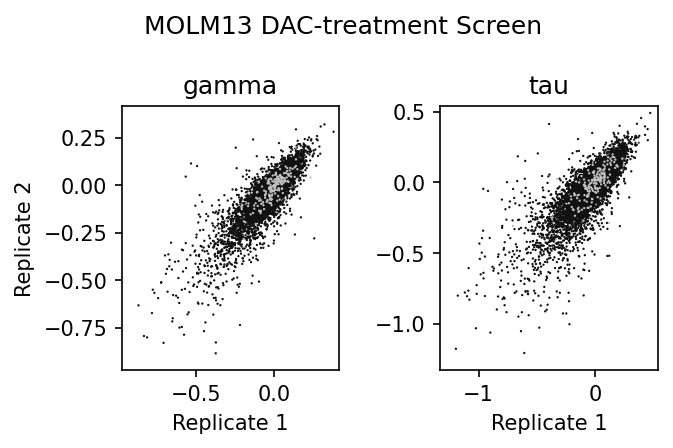

In [71]:
_, (ax1,ax2) = plt.subplots(1,2,figsize=(4.5,3),dpi=150)

scp.pl.plotReplicateScatter(ax1, molm13_screen.pdata,
                            'gamma:DMSO_vs_T0::replicate_1',
                            'gamma:DMSO_vs_T0::replicate_2', title='gamma',log_transform=False)
scp.pl.plotReplicateScatter(ax2, molm13_screen.pdata,
                            'tau:DAC_vs_T0::replicate_1',
                            'tau:DAC_vs_T0::replicate_2',
                            title='tau',log_transform=False)
ax2.set_ylabel('')

plt.suptitle('MOLM13 DAC-treatment Screen')
plt.tight_layout()
plt.show()

# 

In [72]:
# pdata = ad.AnnData(X=phe,var=oligo)

# pdata.obs['cell_line'] = pdata.obs.index.str.split('_').str[0]
# pdata.obs['score'] = pdata.obs.index.str.split('_').str[1]
# pdata.obs['replicate'] = pdata.obs.index.str.split('_').str[-1]

# pdata_filt = pd.concat(dict([(line,screens[line].adata.var['low_count']) for line in screens]),axis=1).sum(axis=1).gt(0)

# pdata = pdata[:,~pdata_filt].copy()

In [73]:
# pdata0 = pdata.copy()

In [74]:
# pdata = pdata0[pdata0.obs.score.isin(['rho','gamma'])].copy()

### 

In [75]:
# sc.tl.pca(pdata)#, svd_solver='arpack')

In [76]:
# with rc_context({'figure.figsize': (3, 3)}):
#     sc.pl.pca_variance_ratio(pdata, n_pcs=8)
#     plt.tight_layout()
#     plt.show()

In [77]:
# with rc_context({'figure.figsize': (2, 2)}):
#     sc.pl.pca_scatter(pdata,color='score',size=300,alpha=0.7)
#     sc.pl.pca_scatter(pdata,color='cell_line',size=300,alpha=0.7)

In [78]:
# pca = plot_ggplot_pca(pdata,fill = 'cell_line',shape='score',legend_position=None,figure_size= (6, 3.5))

# 

In [79]:
%reload_ext watermark

In [80]:
%watermark

Last updated: 2026-03-12T16:43:55.224526-07:00

Python implementation: CPython
Python version       : 3.11.15
IPython version      : 9.10.0

Compiler    : GCC 14.3.0
OS          : Linux
Release     : 4.18.0-513.9.1.el8_9.x86_64
Machine     : x86_64
Processor   : x86_64
CPU cores   : 64
Architecture: 64bit



In [81]:
%watermark --iversions

anndata          : 0.11.4
blitzgsea        : 1.3.54
matplotlib       : 3.10.8
matplotlib_inline: 0.2.1
numpy            : 2.4.2
pandas           : 3.0.1
scanpy           : 1.11.0
scipy            : 1.17.1
screenpro        : 0.6.1
sklearn          : 1.5.2



In [82]:
!date

Thu Mar 12 16:43:56 PDT 2026


___